In [ ]:
%%capture
import os, re
if "COLAB_" not in "".join(os.environ.keys()):
    !pip install "unsloth==2026.1.3"
else:
    # Do this only in Colab notebooks! Otherwise use pip install unsloth
    import torch; v = re.match(r"[0-9]{1,}\.[0-9]{1,}", str(torch.__version__)).group(0)
    xformers = "xformers==" + ("0.0.33.post1" if v=="2.9" else "0.0.32.post2" if v=="2.8" else "0.0.29.post3")
    !pip install --no-deps bitsandbytes accelerate {xformers} peft trl triton cut_cross_entropy unsloth_zoo
    !pip install sentencepiece protobuf "datasets==4.3.0" "huggingface_hub>=0.34.0" hf_transfer
    !pip install --no-deps "unsloth==2026.1.3"
!pip install transformers==4.56.2
!pip install --no-deps trl==0.22.2

In [ ]:
 from unsloth import FastVisionModel # FastLanguageModel for LLMs
import torch

model, processor = FastVisionModel.from_pretrained(
    "unsloth/gemma-3-4b-it",
    load_in_4bit = True, # Use 4bit to reduce memory use. False for 16bit LoRA.
    use_gradient_checkpointing = "unsloth", # True or "unsloth" for long context
)

🦥 Unsloth: Will patch your computer to enable 2x faster free finetuning.
🦥 Unsloth Zoo will now patch everything to make training faster!
==((====))==  Unsloth 2026.1.3: Fast Gemma3 patching. Transformers: 4.56.2.
   \\   /|    Tesla T4. Num GPUs = 1. Max memory: 14.563 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.10.0+cu128. CUDA: 7.5. CUDA Toolkit: 12.8. Triton: 3.6.0
\        /    Bfloat16 = FALSE. FA [Xformers = None. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!
Unsloth: Using float16 precision for gemma3 won't work! Using float32.
Unsloth: Gemma3 does not support SDPA - switching to fast eager.


model.safetensors:   0%|          | 0.00/4.56G [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/210 [00:00<?, ?B/s]

processor_config.json:   0%|          | 0.00/70.0 [00:00<?, ?B/s]

chat_template.json: 0.00B [00:00, ?B/s]

...

tokenizer_config.json: 0.00B [00:00, ?B/s]

tokenizer.model:   0%|          | 0.00/4.69M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/33.4M [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/35.0 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/670 [00:00<?, ?B/s]

In [ ]:
from unsloth import get_chat_template

processor = get_chat_template(
    processor,
    "gemma-3"
)

In [ ]:
from datasets import load_dataset
test_ds = load_dataset(
    "123ccls/POLCOVID_task2_70_10_20",  # 🔁 CHANGE THIS
    split="test"
)

README.md:   0%|          | 0.00/624 [00:00<?, ?B/s]

data/train-00000-of-00001.parquet:   0%|          | 0.00/303M [00:00<?, ?B/s]

data/validation-00000-of-00001.parquet:   0%|          | 0.00/43.2M [00:00<?, ?B/s]

data/test-00000-of-00001.parquet:   0%|          | 0.00/87.4M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/1596 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/228 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/456 [00:00<?, ? examples/s]

In [ ]:
from pathlib import Path
import pandas as pd
import re

TASK_ID = "Task2_base"
RESULTS_PROJECT_ROOT = Path(
    r"C:\Users\Henryayay\OneDrive - The Hong Kong Polytechnic University\Desktop\AI xray classification project\Results"
)
LOCAL_RESULTS_ROOT = RESULTS_PROJECT_ROOT / "ICL" / "Task2"

def _slug(text):
    text = str(text).strip().replace(" ", "-")
    return re.sub(r"[^A-Za-z0-9._-]+", "_", text)

def record_and_save_run(y_true, y_pred, setup, model, accuracy_pct, task_id=TASK_ID, trigger_download=True, name_to_id=None):
    """Save predictions under Results/<method>/<task>/ with task, setup, model, and accuracy in the filename."""
    if name_to_id is None:
        name_to_id = NAME_TO_ID if 'NAME_TO_ID' in globals() else {"Non-COVID Pneumonia": 0, "COVID-19": 1}
    y_true = list(y_true)
    y_pred = list(y_pred)
    df = pd.DataFrame({
        "Index": range(len(y_true)),
        "True_Label_ID": [name_to_id.get(str(v).strip(), -1) for v in y_true],
        "Predicted_Label_ID": [name_to_id.get(str(v).strip(), -1) for v in y_pred],
        "True_Label_Name": y_true,
        "Predicted_Label_Name": y_pred,
    })

    acc_label = f"{float(accuracy_pct):.2f}pct"
    filename = f"{_slug(task_id)}_{_slug(setup)}_{_slug(model)}_acc{acc_label}.csv"

    dest_dir = None
    for candidate in (LOCAL_RESULTS_ROOT, Path.cwd() / "Results" / "ICL" / "Task2"):
        try:
            candidate.mkdir(parents=True, exist_ok=True)
            probe = candidate / ".write_test"
            probe.write_text("ok", encoding="utf-8")
            probe.unlink()
            dest_dir = candidate
            break
        except Exception:
            continue
    if dest_dir is None:
        dest_dir = Path.cwd() / "Results" / "ICL" / "Task2"
        dest_dir.mkdir(parents=True, exist_ok=True)

    dest_path = dest_dir / filename
    df.to_csv(dest_path, index=False)
    print(f"Saved predictions to: {dest_path}")

    errors = df[df["Predicted_Label_ID"] == -1]
    if len(errors) > 0:
        print(f"WARNING: {len(errors)} predictions could not be mapped to IDs!")
        print(errors["Predicted_Label_Name"].unique())
    else:
        print("Verification Passed: All predictions mapped correctly.")

    saved_on_pc = str(LOCAL_RESULTS_ROOT) in str(dest_path)
    if trigger_download and not saved_on_pc:
        cwd_copy = Path.cwd() / filename
        if cwd_copy.resolve() != dest_path.resolve():
            df.to_csv(cwd_copy, index=False)
        try:
            from google.colab import files
            print(f"Starting download for {filename}")
            print(f"If the browser save dialog appears, choose:\n{LOCAL_RESULTS_ROOT}")
            files.download(str(cwd_copy if cwd_copy.exists() else dest_path))
        except Exception as exc:
            print(f"Could not auto-download to your PC ({exc}). Copy this file to:\n{LOCAL_RESULTS_ROOT}")
    return dest_path


Starting evaluation on test images...


100%|██████████| 456/456 [12:37<00:00,  1.66s/it]



✅ Base Gemma3 Task1 Accuracy: 50.22%

📊 Detailed Report:
                     precision    recall  f1-score   support

Non-COVID Pneumonia       0.50      1.00      0.67       228
           COVID-19       1.00      0.00      0.01       228

           accuracy                           0.50       456
          macro avg       0.75      0.50      0.34       456
       weighted avg       0.75      0.50      0.34       456



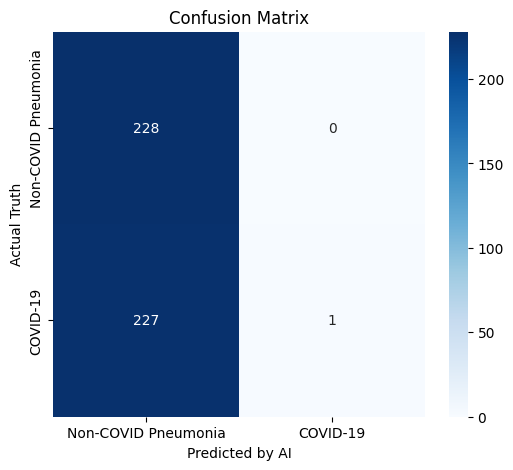

In [ ]:
# ==========================================
# 1. SETUP & IMPORTS
# ==========================================
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
from tqdm import tqdm
import torch

# Ensure model is in inference mode (Unsloth method)
FastVisionModel.for_inference(model)

# Define your labels again just to be safe
LABEL_MAP = {
    0: "Non-COVID Pneumonia",
    1: "COVID-19",
}

# ==========================================
# 2. INFERENCE LOOP (Test all 40 images)
# ==========================================
y_true = []
y_pred = []

print("Starting evaluation on test images...")

for sample in tqdm(test_ds):
    # A. Get the actual Label (Ground Truth)
    actual_label = LABEL_MAP[sample["label"]]
    y_true.append(actual_label)

    # B. Prepare the Image & Instruction
    image = sample["image"]
    instruction = (
    "You are an expert radiologist. Analyze this chest X-ray and classify it as 'Non-COVID Pneumonia' or 'COVID-19'. Output only the diagnosis."
)


    messages = [
        {
            "role": "user",
            "content": [
                {"type": "text", "text": instruction},
                {"type": "image"} # Placeholder
            ],
        }
    ]

    # C. Process Inputs
    input_text = processor.apply_chat_template(messages, add_generation_prompt=True)
    inputs = processor(
        text=input_text,
        images=image,
        add_special_tokens=False,
        return_tensors="pt"
    ).to("cuda")

    # D. Generate Prediction
    output = model.generate(
        **inputs,
        max_new_tokens=30,
        temperature=0.01,   # Low temp = more strict/consistent
        use_cache=True
    )

    # E. Decode the answer
    # We slice [:, inputs.input_ids.shape[1]:] to remove the prompt and keep only the answer
    response = processor.batch_decode(output[:, inputs.input_ids.shape[1]:], skip_special_tokens=True)[0]


    if "COVID-19" in response:
        pred_label = "COVID-19"
    elif "Non-COVID Pneumonia" in response:
        pred_label = "Non-COVID Pneumonia"
    else:
        pred_label = "Error"

    y_pred.append(pred_label)


# ==========================================
# CALCULATE METRICS & PLOT
# ==========================================

# 1. Calculate Accuracy
acc = accuracy_score(y_true, y_pred)
accuracy_pct = acc * 100

# 2. Print Text Reports
print(f"\n✅ Base Gemma3 Task1 Accuracy: {accuracy_pct:.2f}%")
print("\n📊 Detailed Report:")
print(classification_report(y_true, y_pred, labels=["Non-COVID Pneumonia", "COVID-19"]))


# C. Confusion Matrix
cm = confusion_matrix(y_true, y_pred, labels=["Non-COVID Pneumonia", "COVID-19"])

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=["Non-COVID Pneumonia", "COVID-19"],
            yticklabels=["Non-COVID Pneumonia", "COVID-19"])
plt.xlabel('Predicted by AI')
plt.ylabel('Actual Truth')
plt.title('Confusion Matrix')
plt.show()


In [ ]:
import pandas as pd

# ==========================================
# CELL: SAVE PREDICTIONS TO CSV
# ==========================================

# 1. Define Robust Map
# Handles both "Non-COVID Pneumonia" and "COVID-19" to prevent errors
NAME_TO_ID = {
    "Non-COVID Pneumonia": 0,
    "COVID-19": 1
}

# 2. Convert Names to IDs safely
y_true_ids = []
y_pred_ids = []

for val in y_true:
    # Remove extra spaces/punctuation just in case
    clean_val = str(val).strip()
    y_true_ids.append(NAME_TO_ID.get(clean_val, -1)) # Returns -1 if unknown

for val in y_pred:
    clean_val = str(val).strip()
    y_pred_ids.append(NAME_TO_ID.get(clean_val, -1))

# 3. Create DataFrame (5 Columns)

record_and_save_run(
    y_true,
    y_pred,
    setup="base",
    model="gemma-3-4b-it",
    accuracy_pct=accuracy_pct,
)


Success! Saved predictions to: base_gemma3_task1_predictions.csv
------------------------------
   Index  True_Label_ID  Predicted_Label_ID      True_Label_Name  \
0      0              1                   0             COVID-19   
1      1              1                   0             COVID-19   
2      2              1                   0             COVID-19   
3      3              0                   0  Non-COVID Pneumonia   
4      4              0                   0  Non-COVID Pneumonia   

  Predicted_Label_Name  
0  Non-COVID Pneumonia  
1  Non-COVID Pneumonia  
2  Non-COVID Pneumonia  
3  Non-COVID Pneumonia  
4  Non-COVID Pneumonia  

Verification Passed: All predictions mapped correctly.
